In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score
from sklearn.preprocessing import StandardScaler

In [2]:
from sklearn.datasets import fetch_california_housing
housing=fetch_california_housing()
df=pd.DataFrame(housing.data,columns=housing.feature_names)
print(housing.feature_names)
df['HouseVal']=housing.target
print(df.head())
print(df.isnull().sum())

['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  HouseVal  
0    -122.23     4.526  
1    -122.22     3.585  
2    -122.24     3.521  
3    -122.25     3.413  
4    -122.25     3.422  
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
HouseVal      0
dtype: int64


In [3]:
Q1,Q3=df['AveRooms'].quantile([0.25,0.75])
IQR=Q3-Q1
lower,upper=Q1-1.5*IQR,Q3+1.5*IQR
mask=(df['AveRooms']>=lower)&(df['AveRooms']<=upper)
df_clean=df.loc[mask].reset_index(drop=True)
print(f"Removed {len(df)-len(df_clean)} outlier rows; {len(df_clean)} remain.")
x=df_clean[['AveRooms']].values
y=df_clean['HouseVal'].values

Removed 511 outlier rows; 20129 remain.


In [4]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)
print("Split done")

Split done


In [5]:
#scale
scalar=StandardScaler()
scalar.fit(x_train)
x_train_scaled=scalar.transform(x_train)
x_test_scaled=scalar.transform(x_test)
print("Mean/std used for scaling:",scalar.mean_,scalar.scale_)

Mean/std used for scaling: [5.2445748] [1.15439852]


In [6]:
def normal_equation(x,y):
    m=x.shape[0]
    x_b=np.c_[np.ones((m,1)),x]
    theta=np.linalg.inv(x_b.T@x_b)@x_b.T@y
    return theta
theta_ne=normal_equation(x_train_scaled,y_train)
b_ne,w_ne=theta_ne[0],theta_ne[1]
print(f"Normal equation parameters")
print(f"Intercept:{b_ne:.4f}, Slope:{w_ne:.4f}")

Normal equation parameters
Intercept:2.0581, Slope:0.3662


In [7]:
def predict(x,w,b):
    return w*x.ravel()+b
y_pred=predict(x_test_scaled,w_ne,b_ne)
print(y_pred)

[1.89664984 1.55816522 1.91741673 ... 2.25792675 2.53992263 1.26072053]


In [8]:
predictions=pd.DataFrame({"Actual":y_test,"Predicted":y_pred})
print(predictions.head())

    Actual  Predicted
0  3.20800   1.896650
1  1.70300   1.558165
2  5.00001   1.917417
3  1.93800   1.733620
4  2.78700   2.782220


In [9]:
mse=mean_squared_error(y_test,y_pred)
print(f"Mean squared error:{mse:.4f}")
r2=r2_score(y_test,y_pred)
print(f"R-squared error:{r2:.4f}")

Mean squared error:1.1852
R-squared error:0.0846


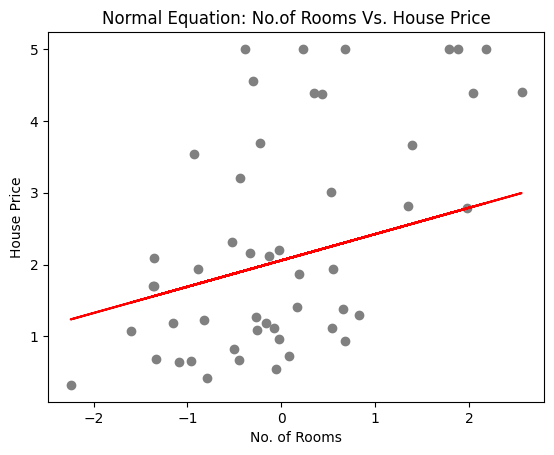

In [10]:
plt.scatter(x_test_scaled[:50],y_test[:50],color='gray')
plt.plot(x_test_scaled[:50],y_pred[:50],color='red')
plt.xlabel('No. of Rooms')
plt.ylabel('House Price')
plt.title('Normal Equation: No.of Rooms Vs. House Price')
plt.show()

Text(0.5, 1.0, 'Residual Distribution')

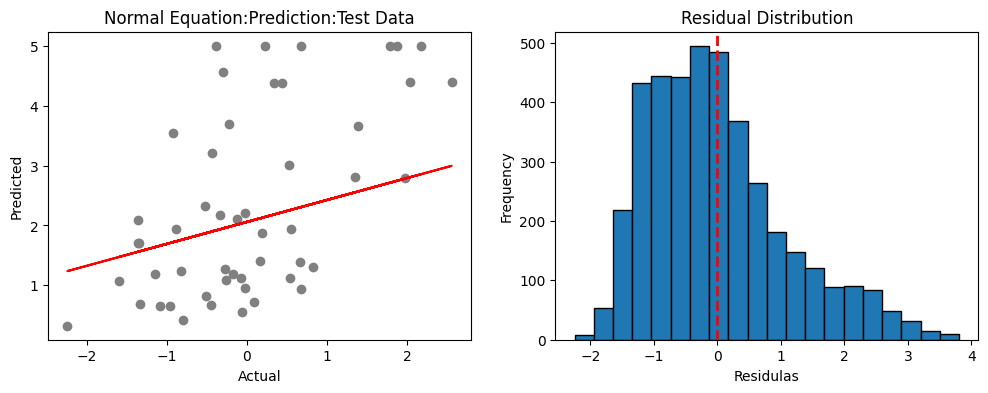

In [11]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(x_test_scaled[:50],y_test[:50],color='gray')
axes[0].plot(x_test_scaled[:50],y_pred[:50],color='red',label='Regression')
axes[0].set_xlabel('Actual')
axes[0].set_ylabel('Predicted')
axes[0].set_title('Normal Equation:Prediction:Test Data')
residuals=y_test-y_pred
axes[1].hist(residuals,bins=20,edgecolor='black')
axes[1].axvline(x=0,color='red',linestyle='dashed',linewidth=2)
axes[1].set_xlabel('Residulas')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Residual Distribution')

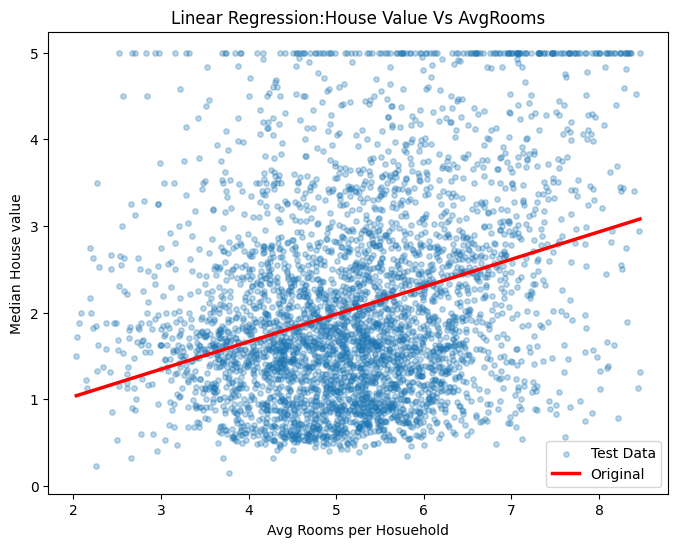

In [12]:
x_line_scaled=np.linspace(x_test_scaled.min(),x_test_scaled.max(),200).reshape(-1,1)
y_line=predict(x_line_scaled,w_ne,b_ne)
x_line_original=scalar.inverse_transform(x_line_scaled).ravel()
plt.figure(figsize=(8,6))
plt.scatter(x_test,y_test,alpha=0.3,s=15,label="Test Data")
plt.plot(x_line_original,y_line,color="red",linewidth=2.5,label="Original")
plt.xlabel("Avg Rooms per Hosuehold")
plt.ylabel("Median House value")
plt.title("Linear Regression:House Value Vs AvgRooms")
plt.legend()
plt.show()

In [13]:
def compute_cost(x,y,w,b):
    m=len(y)
    predictions=w*x.ravel()+b
    cost=(1/(2*m))*np.sum((predictions-y)**2)
    return cost

def grad_desc(x,y,w_init=0.0,b_init=0.0,alpha=0.1,n_iteration=1000):
    m=len(y)
    w,b=w_init,b_init
    cost_history=[]
    for i in range(n_iteration):
        predictions=w*x.ravel()+b
        error=predictions-y
        dw=(1/m)*np.dot(error,x.ravel())
        db=(1/m)*np.sum(error)
        w-=alpha*dw
        b-=alpha*db
        cost=compute_cost(x,y,w,b)
        cost_history.append(cost)
        if (i%100)==0:
            print(f"Iteration:{i:4d} Cost={cost:.5f} w={w:.4f} b={b:.4f}")
    return w,b,cost_history
w_gd,b_gd,cost_hist=grad_desc(x_train_scaled,y_train,w_init=0.0,b_init=0.0,alpha=0.1,n_iteration=1000)
print(f"Final Parameters w={w_gd:.4f} b={b_gd:.4f}")

Iteration:   0 Cost=2.34879 w=0.0366 b=0.2058
Iteration: 100 Cost=0.57907 w=0.3662 b=2.0580
Iteration: 200 Cost=0.57907 w=0.3662 b=2.0581
Iteration: 300 Cost=0.57907 w=0.3662 b=2.0581
Iteration: 400 Cost=0.57907 w=0.3662 b=2.0581
Iteration: 500 Cost=0.57907 w=0.3662 b=2.0581
Iteration: 600 Cost=0.57907 w=0.3662 b=2.0581
Iteration: 700 Cost=0.57907 w=0.3662 b=2.0581
Iteration: 800 Cost=0.57907 w=0.3662 b=2.0581
Iteration: 900 Cost=0.57907 w=0.3662 b=2.0581
Final Parameters w=0.3662 b=2.0581


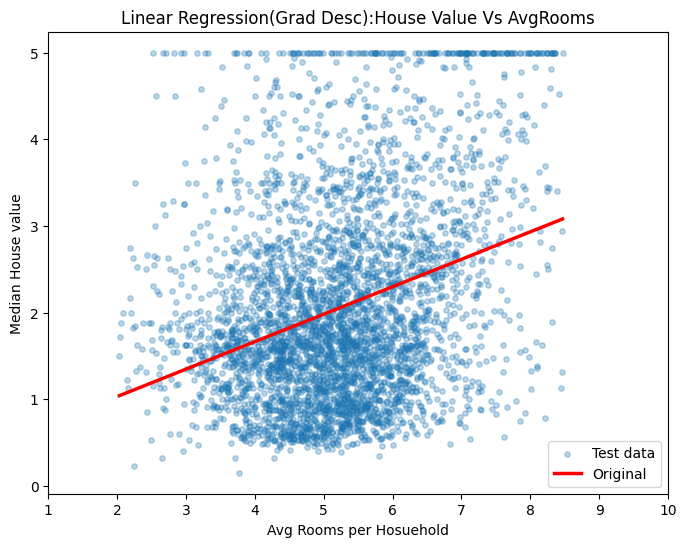

In [24]:
def predict_grad(x,w,b):
    return  w*x.ravel()+b
y_pred_grad=predict_grad(x_test_scaled,w_gd,b_gd)
x_line_scaled_grad=np.linspace(x_test_scaled.min(),x_test_scaled.max(),200).reshape(-1,1)
y_line_grad=predict_grad(x_line_scaled_grad,w_gd,b_gd)
x_line_original_grad=scalar.inverse_transform(x_line_scaled_grad).ravel()
plt.figure(figsize=(8,6))
plt.scatter(x_test,y_test,alpha=0.3,s=15,label="Test data")
plt.plot(x_line_original_grad,y_line_grad,color="red",linewidth=2.5,label="Original")
plt.xlabel("Avg Rooms per Hosuehold")
plt.ylabel("Median House value")
plt.title("Linear Regression(Grad Desc):House Value Vs AvgRooms")
plt.legend()
plt.xlim(1,10)
plt.show()

In [19]:
print("Mean Square Error:",mean_squared_error(y_pred_grad,y_test))
print("R2 Score:",r2_score(y_test,y_pred_grad))

Mean Square Error: 1.1851859323405967
R2 Score: 0.08456637521347232
